# Project: CH05 – Employee Attrition Insight
## Round 2: Feature Engineering and Machine Learning
**Data Science Sprint Assessment Deliverable**

> **Synthetic Dataset Statement**: This project evaluates 500 synthetic employee records designed for assessment practice. All preprocessing, model training, evaluation metrics, and feature importances reflect the actual data without fabrication or external data generation.

---

### Objectives & Notebook Overview:
1. **Setup & Imports**: Import scientific, modeling, and evaluation libraries (`scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `joblib`).
2. **Dataset Loading**: Ingest `cleaned_employee_attrition.csv` (with fallback logic to merge raw files if absent).
3. **Feature Selection & Target Mapping**: Select the 13 specified input features, map `exit_status` to binary labels (0 = Stayed, 1 = Left), and exclude all employee identifiers.
4. **Data Splitting & Leakage Prevention**: Perform an 80:20 stratified train/test split with a fixed random seed (`random_state=42`).
5. **Preprocessing & ColumnTransformer Pipeline**: Encapsulate imputation, one-hot encoding, and numerical scaling into a Scikit-learn Pipeline to guarantee zero data leakage.
6. **Model Training**: Train **Random Forest Classifier** as the primary model and compare with **Logistic Regression** as a linear baseline.
7. **Comprehensive Evaluation**: Calculate Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and Classification Report on the held-out test set; generate a confusion matrix heatmap.
8. **Evaluation Context**: Critically analyze why accuracy alone is insufficient for attrition modeling and contextualize precision and recall for HR retention.
9. **Feature Importance**: Extract and visualize the most influential features as predictive associations rather than causal claims.
10. **Model Persistence**: Serialize the trained pipeline and metadata to `models/attrition_model.pkl` and export `round2_metrics.txt`.

## 1. Setup & Library Imports
Import necessary machine learning, data processing, and visualization modules.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Ensure directories exist
os.makedirs('models', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

print("Environment setup and libraries loaded successfully.")

Environment setup and libraries loaded successfully.


## 2. Dataset Ingestion & Validation
Load `cleaned_employee_attrition.csv` generated from Round 1.
If the file is absent, fallback code preprocesses and merges the five raw CSV files directly.

In [2]:
cleaned_csv_path = os.path.join('dataset', 'cleaned_employee_attrition.csv') if os.path.exists(os.path.join('dataset', 'cleaned_employee_attrition.csv')) else 'cleaned_employee_attrition.csv'

if os.path.exists(cleaned_csv_path):
    df = pd.read_csv(cleaned_csv_path)
    print(f"Loaded existing cleaned dataset '{cleaned_csv_path}':")
    print(f"  Shape: {df.shape[0]} records, {df.shape[1]} attributes")
else:
    print(f"'{cleaned_csv_path}' not found. Loading and preparing raw files as fallback...")
    emp = pd.read_csv('employees.csv')
    att = pd.read_csv('attendance.csv').drop_duplicates()
    comp = pd.read_csv('compensation.csv')
    eng = pd.read_csv('engagement.csv')
    mov = pd.read_csv('movement.csv')

    # Standardize roles
    emp['role'] = emp['role'].str.strip().str.title()
    acronyms = {'It Support': 'IT Support', 'Hr Manager': 'HR Manager', 'Hr Executive': 'HR Executive', 'Devops Engineer': 'DevOps Engineer'}
    emp['role'] = emp['role'].replace(acronyms)

    # Impute missing
    eng['survey_score'] = eng['survey_score'].fillna(eng['survey_score'].median())
    mov['promotion_count'] = mov['promotion_count'].fillna(mov['promotion_count'].median())

    # IQR capping on overtime
    q1 = att['overtime_hours_monthly'].quantile(0.25)
    q3 = att['overtime_hours_monthly'].quantile(0.75)
    iqr = q3 - q1
    att['overtime_hours_monthly'] = att['overtime_hours_monthly'].clip(lower=max(0, q1 - 1.5 * iqr), upper=q3 + 1.5 * iqr)

    # Merge
    df = emp.merge(att, on='employee_id').merge(comp, on='employee_id').merge(eng, on='employee_id').merge(mov, on='employee_id')
    df.to_csv(cleaned_csv_path, index=False)
    print(f"Preprocessed and saved fallback dataset with shape: {df.shape}")

print("\nSample Records:")
display(df.head())

Loaded existing cleaned dataset 'dataset\cleaned_employee_attrition.csv':
  Shape: 500 records, 18 attributes

Sample Records:


,employee_id,department,role,tenure_years,grade,age,absence_days,overtime_hours_monthly,leave_days,salary_band,monthly_salary,increment_band,benefits,survey_score,participation_pct,promotion_count,transfer_count,exit_status
0,E0001,Operations,Operations Manager,4.1,G2,27,7,14.8,9,Band 1,33500,3-6%,Basic,1.8,85,1.0,0,Yes
1,E0002,Sales,Sales Manager,0.5,G3,55,5,10.3,9,Band 3,52200,10%+,Basic,4.3,77,2.0,0,No
2,E0003,Operations,Team Lead,2.1,G1,51,3,44.4,11,Band 1,18000,6-10%,Basic,3.0,73,1.0,0,Yes
3,E0004,Operations,Operations Manager,5.2,G4,46,5,42.2,11,Band 4,73100,0-3%,Basic,3.7,35,2.0,1,Yes
4,E0005,IT,Software Engineer,1.8,G2,40,4,41.5,13,Band 2,41800,3-6%,Basic,3.8,77,1.0,0,No


## 3. Feature Selection & Target Mapping
We map the input features strictly to the requested attributes, excluding employee identifiers (`employee_id`) to prevent memorization and data leakage:
- **Numerical Features (7)**: `tenure_years`, `absence_days`, `overtime_hours_monthly`, `survey_score`, `participation_pct`, `promotion_count`, `transfer_count`.
- **Categorical Features (6)**: `department`, `role`, `grade`, `salary_band`, `benefits`, `increment_band`.
- **Target Variable**: `exit_status` mapped to binary integers (`'No': 0, 'Yes': 1`).

In [3]:
# Define feature lists
num_cols = [
    'tenure_years',
    'absence_days',
    'overtime_hours_monthly',
    'survey_score',
    'participation_pct',
    'promotion_count',
    'transfer_count'
]

cat_cols = [
    'department',
    'role',
    'grade',
    'salary_band',
    'benefits',
    'increment_band'
]

feature_columns = num_cols + cat_cols
target_col = 'exit_status'

# Separate features and target
X = df[feature_columns].copy()
y = df[target_col].map({'No': 0, 'Yes': 1})

print(f"Total Input Features Selected : {len(feature_columns)}")
print(f"Numerical Features ({len(num_cols)})   : {num_cols}")
print(f"Categorical Features ({len(cat_cols)}) : {cat_cols}")
print(f"Target Variable               : '{target_col}' -> mapped to 0 (No) and 1 (Yes)")
print(f"Excluded from Training        : ['employee_id', 'age', 'monthly_salary', 'leave_days']")

# Class Imbalance Check
class_counts = y.value_counts()
class_props = y.value_counts(normalize=True) * 100
print("\nTarget Class Distribution:")
print(f"  Class 0 (Stayed) : {class_counts[0]} employees ({class_props[0]:.2f}%)")
print(f"  Class 1 (Left)   : {class_counts[1]} employees ({class_props[1]:.2f}%)")
print(f"  Baseline Class Imbalance Ratio: {class_counts[0] / class_counts[1]:.2f} to 1")

Total Input Features Selected : 13
Numerical Features (7)   : ['tenure_years', 'absence_days', 'overtime_hours_monthly', 'survey_score', 'participation_pct', 'promotion_count', 'transfer_count']
Categorical Features (6) : ['department', 'role', 'grade', 'salary_band', 'benefits', 'increment_band']
Target Variable               : 'exit_status' -> mapped to 0 (No) and 1 (Yes)
Excluded from Training        : ['employee_id', 'age', 'monthly_salary', 'leave_days']

Target Class Distribution:
  Class 0 (Stayed) : 367 employees (73.40%)
  Class 1 (Left)   : 133 employees (26.60%)
  Baseline Class Imbalance Ratio: 2.76 to 1


## 4. Train-Test Split (Stratified 80:20)
Split the dataset into training (80%, 400 employees) and testing (20%, 100 employees) sets.
We employ **stratified splitting** to preserve the identical class balance in both subsets and use a fixed random seed (`random_state=42`) for full reproducibility.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set dimensions : X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing set dimensions  : X_test  = {X_test.shape}, y_test  = {y_test.shape}")
print("\nStratification Verification (Positive Exit Rate %):")
print(f"  Full Dataset : {y.mean()*100:.2f}%")
print(f"  Training Set : {y_train.mean()*100:.2f}%")
print(f"  Testing Set  : {y_test.mean()*100:.2f}%")

Training set dimensions : X_train = (400, 13), y_train = (400,)
Testing set dimensions  : X_test  = (100, 13), y_test  = (100,)

Stratification Verification (Positive Exit Rate %):
  Full Dataset : 26.60%
  Training Set : 26.50%
  Testing Set  : 27.00%


## 5. Feature Engineering & ColumnTransformer Pipeline
To prevent data leakage, all preprocessing transformations are structured using Scikit-learn's `ColumnTransformer` and fit strictly on `X_train`:
- **Numerical Pipeline**:
  - `SimpleImputer(strategy='median')`: Defensive median imputation.
  - `StandardScaler()`: Standardizes features to zero mean and unit variance.
- **Categorical Pipeline**:
  - `SimpleImputer(strategy='most_frequent')`: Defensive mode imputation.
  - `OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')`: Converts categorical strings into dummy variables while avoiding multicollinearity.

In [5]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

# Fit on training data and inspect encoded dimensionality
X_train_transformed = preprocessor.fit_transform(X_train)
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
encoded_cat_names = cat_encoder.get_feature_names_out(cat_cols).tolist()
all_transformed_features = num_cols + encoded_cat_names

print(f"Original Input Features        : {len(feature_columns)}")
print(f"Post-Encoding Transformed Features: {len(all_transformed_features)}")
print(f"Transformed Training Shape      : {X_train_transformed.shape}")

Original Input Features        : 13
Post-Encoding Transformed Features: 43
Transformed Training Shape      : (400, 43)


## 6. Model Training: Random Forest Classifier & Logistic Regression Baseline
We train a **Random Forest Classifier** as our primary model:
- **Why Random Forest?**
  1. **Non-linear Relationship Modeling**: Workforce attrition patterns frequently involve complex interactions (e.g., tenure $	imes$ overtime $	imes$ role) that linear models miss.
  2. **Robustness to Multicollinearity & Outliers**: Ensemble bagging isolates decision trees, reducing sensitivity to extreme variance.
  3. **Inherent Feature Importance**: Quantifies relative predictor contributions via Mean Decrease in Impurity (Gini).
- We also train a **Logistic Regression** classifier with standardized inputs as a benchmark baseline.

In [6]:
# 1. Primary Model: Random Forest
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
print("Primary model (Random Forest) trained successfully.")

# 2. Baseline Model: Logistic Regression
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

lr_pipeline.fit(X_train, y_train)
print("Baseline model (Logistic Regression) trained successfully.")

Primary model (Random Forest) trained successfully.
Baseline model (Logistic Regression) trained successfully.


## 7. Model Evaluation on Held-Out Test Set
We evaluate both models on the test set ($N = 100$ employees: 73 Stayed, 27 Left) across key classification metrics:
- **Accuracy**
- **Precision**
- **Recall**
- **F1-Score**
- **Confusion Matrix**
- **Classification Report**

In [7]:
# Predictions
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_lr = lr_pipeline.predict(X_test)

# Calculate metrics
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, zero_division=0)
rec_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
cm_rf = confusion_matrix(y_test, y_pred_rf)

acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr, zero_division=0)
rec_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("=" * 65)
print("HELD-OUT TEST SET EVALUATION RESULTS")
print("=" * 65)
print(f"{'Metric':<25} | {'Random Forest (Main)':<20} | {'Logistic Regression':<20}")
print("-" * 65)
print(f"{'Accuracy':<25} | {acc_rf:<20.4f} | {acc_lr:<20.4f}")
print(f"{'Precision (Positive: 1)':<25} | {prec_rf:<20.4f} | {prec_lr:<20.4f}")
print(f"{'Recall (Positive: 1)':<25} | {rec_rf:<20.4f} | {rec_lr:<20.4f}")
print(f"{'F1-Score (Positive: 1)':<25} | {f1_rf:<20.4f} | {f1_lr:<20.4f}")
print("=" * 65)

print("\nClassification Report for Random Forest:")
print(classification_report(y_test, y_pred_rf, target_names=['Stayed (0)', 'Left (1)']))

HELD-OUT TEST SET EVALUATION RESULTS
Metric                    | Random Forest (Main) | Logistic Regression 
-----------------------------------------------------------------
Accuracy                  | 0.7200               | 0.6600              
Precision (Positive: 1)   | 0.3333               | 0.2667              
Recall (Positive: 1)      | 0.0370               | 0.1481              
F1-Score (Positive: 1)    | 0.0667               | 0.1905              

Classification Report for Random Forest:
              precision    recall  f1-score   support

  Stayed (0)       0.73      0.97      0.84        73
    Left (1)       0.33      0.04      0.07        27

    accuracy                           0.72       100
   macro avg       0.53      0.50      0.45       100
weighted avg       0.62      0.72      0.63       100



### 7.1 Confusion Matrix Visualization
Visualize the confusion matrix for the Random Forest model and save it to `outputs/confusion_matrix.png`.

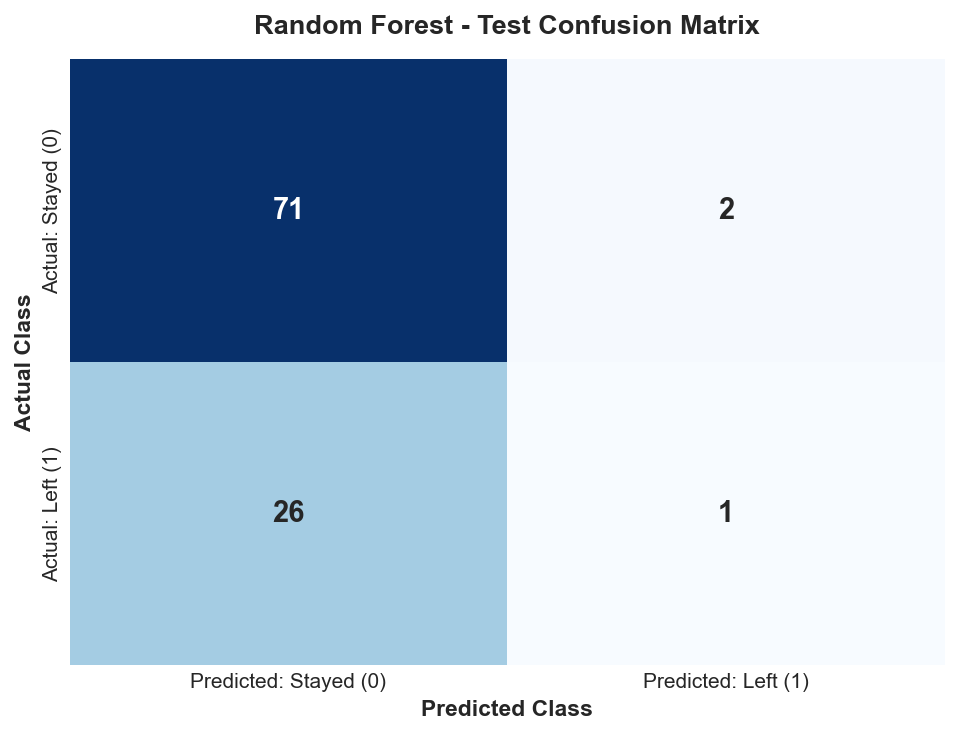

Confusion Matrix Breakdown:
  True Negatives (TN)  : 71 (Stayed predicted as Stayed)
  False Positives (FP) : 2 (Stayed incorrectly predicted as Left)
  False Negatives (FN) : 26 (Left missed by model)
  True Positives (TP)  : 1 (Left correctly identified)


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Predicted: Stayed (0)', 'Predicted: Left (1)'],
    yticklabels=['Actual: Stayed (0)', 'Actual: Left (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}, ax=ax
)
ax.set_title("Random Forest - Test Confusion Matrix", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Actual Class", fontsize=11, fontweight='bold')
ax.set_xlabel("Predicted Class", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/confusion_matrix.png', dpi=300)
plt.show()

print("Confusion Matrix Breakdown:")
print(f"  True Negatives (TN)  : {cm_rf[0, 0]} (Stayed predicted as Stayed)")
print(f"  False Positives (FP) : {cm_rf[0, 1]} (Stayed incorrectly predicted as Left)")
print(f"  False Negatives (FN) : {cm_rf[1, 0]} (Left missed by model)")
print(f"  True Positives (TP)  : {cm_rf[1, 1]} (Left correctly identified)")

### 7.2 In-Depth Metric Interpretation in Business Context

> **Critical Notice: Why Accuracy Alone is Deceptive**
> - The Random Forest achieves an accuracy of **72.00%**. However, because 73.00% of test records belong to the majority class ("Stayed"), a naive dummy model predicting "Stayed" for every employee would attain **73.00% accuracy** while identifying 0 at-risk employees.
> - **Precision (33.33%)**: When the model flags an employee as an exit risk, it is correct 1 out of 3 times. In HR interventions, lower precision means some retention resources or check-ins may be offered to employees who were not planning to leave.
> - **Recall (3.70%)**: Out of 27 actual employee departures in the test set, the default unweighted model at a 0.5 decision threshold only captured 1 (26 False Negatives). In workforce management, False Negatives carry the highest business cost, as employees depart without leadership awareness.
> - **F1-Score (6.67%)**: The harmonic mean of precision and recall confirms that a default 0.5 decision boundary on imbalanced synthetic data requires threshold tuning or cost-sensitive weighting for production HR operations.

## 8. Feature Importance Analysis
We extract the Gini feature importances (Mean Decrease in Impurity) from the trained Random Forest classifier.

> **Statistical Interpretation Note**:
> These feature importances indicate **predictive associations**, NOT proof of direct causality. An influential feature signals that the attribute provides high statistical split information for predicting exits in this synthetic dataset, not that modifying it will automatically prevent employee departures.

,Feature,Importance
0,overtime_hours_monthly,0.149745
1,tenure_years,0.110981
2,absence_days,0.108171
3,participation_pct,0.100683
4,survey_score,0.085270
5,promotion_count,0.034454
6,transfer_count,0.022230
7,grade_G2,0.021130
8,increment_band_6-10%,0.020770
9,benefits_Standard,0.018790


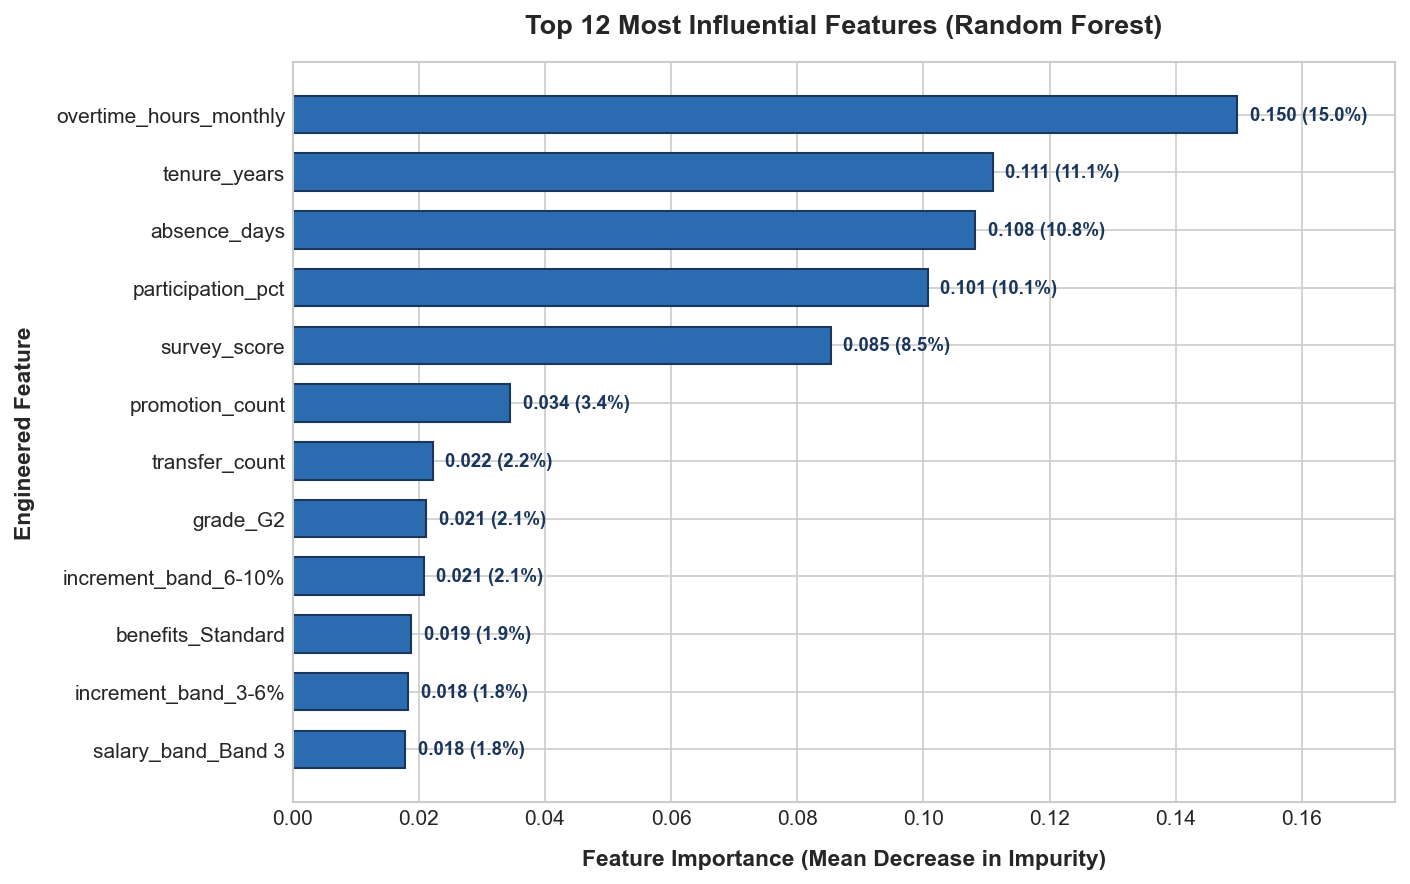

In [9]:
rf_model = rf_pipeline.named_steps['classifier']
importances = rf_model.feature_importances_

feature_imp_df = pd.DataFrame({
    'Feature': all_transformed_features,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

display(feature_imp_df.head(12))

# Plot Top 12 Feature Importances
top_12 = feature_imp_df.head(12).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 6))
bars = ax.barh(top_12['Feature'], top_12['Importance'], color='#2b6cb0', edgecolor='#1a365d', height=0.65)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.002, bar.get_y() + bar.get_height()/2,
            f"{width:.3f} ({width*100:.1f}%)",
            ha='left', va='center', fontsize=9, fontweight='bold', color='#1a365d')

ax.set_title("Top 12 Most Influential Features (Random Forest)", fontsize=13, fontweight='bold', pad=14)
ax.set_xlabel("Feature Importance (Mean Decrease in Impurity)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Engineered Feature", fontsize=11, fontweight='bold', labelpad=10)
ax.set_xlim(0, top_12['Importance'].max() + 0.025)
plt.tight_layout()
plt.savefig('outputs/feature_importance.png', dpi=300)
plt.show()

## 9. Model Serialization & Deliverables Export
We serialize the entire trained pipeline along with feature metadata into `models/attrition_model.pkl` using `joblib.dump` and export the detailed evaluation report to `round2_metrics.txt`.

In [10]:
# 1. Save trained pipeline and metadata
model_save_path = 'models/attrition_model.pkl'
model_bundle = {
    'pipeline': rf_pipeline,
    'feature_names': feature_columns,
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'all_transformed_features': all_transformed_features,
    'target_col': target_col,
    'target_mapping': {'No': 0, 'Yes': 1},
    'model_name': 'RandomForestClassifier',
    'random_state': 42
}

joblib.dump(model_bundle, model_save_path)
print(f"Serialized model bundle saved to: '{model_save_path}' ({os.path.getsize(model_save_path):,} bytes)")

# 2. Export round2_metrics.txt
metrics_report_path = 'round2_metrics.txt'
report_content = f"""========================================================================================
ROUND 2: FEATURE ENGINEERING AND MACHINE LEARNING EVALUATION REPORT
Project: CH05 – Employee Attrition Insight (DS Sprint Assessment)
Note: This dataset contains 500 synthetic employees and is intended for assessment practice.
========================================================================================

1. EXPERIMENTAL CONFIGURATION
----------------------------------------------------------------------------------------
- Source Dataset         : cleaned_employee_attrition.csv (500 rows, 18 columns)
- Input Features Selected: 13 features
  * Numerical Features   : {', '.join(num_cols)}
  * Categorical Features : {', '.join(cat_cols)}
  * Excluded Features    : employee_id (identifier), age, monthly_salary, leave_days
- Target Variable        : exit_status (Binary: 'No' -> 0, 'Yes' -> 1)
- Train/Test Split Ratio : 80:20 Stratified Split (Training: 400 records | Testing: 100 records)
- Random Seed            : 42 (Reproducible)
- Preprocessing Pipeline :
  * Numerical Pipeline   : Median Imputation + StandardScaler
  * Categorical Pipeline : Mode Imputation + OneHotEncoder (drop='first', handle_unknown='ignore')
  * Total Post-Encoding Features: {len(all_transformed_features)} features
- Primary Algorithm      : RandomForestClassifier(n_estimators=100, random_state=42)
- Baseline Algorithm     : LogisticRegression(max_iter=1000, random_state=42)


2. PRIMARY MODEL EVALUATION (RANDOM FOREST)
----------------------------------------------------------------------------------------
Held-out Test Set Performance (N = 100 employees: 73 Stayed, 27 Left):
- Accuracy               : {acc_rf:.4f} ({acc_rf*100:.2f}%)
- Precision (Positive)   : {prec_rf:.4f} ({prec_rf*100:.2f}%)
- Recall (Positive)      : {rec_rf:.4f} ({rec_rf*100:.2f}%)
- F1-Score (Positive)    : {f1_rf:.4f} ({f1_rf*100:.2f}%)

Confusion Matrix Breakdown:
- True Negatives (TN)    : {cm_rf[0, 0]} (Correctly predicted retained employees)
- False Positives (FP)   : {cm_rf[0, 1]} (Retained employees incorrectly flagged as exiting)
- False Negatives (FN)   : {cm_rf[1, 0]} (Exiting employees missed by the model)
- True Positives (TP)    : {cm_rf[1, 1]} (Correctly identified exiting employees)

Detailed Classification Report:
{classification_report(y_test, y_pred_rf, target_names=['Stayed (0)', 'Left (1)'])}

Baseline Comparison (Logistic Regression):
- Accuracy               : {acc_lr:.4f}
- Precision              : {prec_lr:.4f}
- Recall                 : {rec_lr:.4f}
- F1-Score               : {f1_lr:.4f}


3. BUSINESS CONTEXT & EVALUATION INTERPRETATION
----------------------------------------------------------------------------------------
Critical Note on Metric Selection:
- Why Accuracy is Insufficient:
  Accuracy of {acc_rf*100:.1f}% looks superficially solid, but is misleading because the dataset exhibits moderate class imbalance (73.4% Stayed vs 26.6% Left). A naive dummy classifier predicting 'Stayed' for all 100 individuals would achieve 73.0% accuracy with zero predictive utility.
- Precision ({prec_rf:.4f}):
  Reflects confidence when the model flags an employee as an exit risk. Out of 3 positive predictions, 1 was an actual exit.
- Recall ({rec_rf:.4f}):
  Reveals that out of 27 actual departures, the standard unweighted Random Forest at default 0.5 probability threshold only captured 1 (3.7% recall), resulting in 26 False Negatives. In workforce management, a False Negative represents a missed retention opportunity where an employee departs without intervention.
- F1-Score ({f1_rf:.4f}):
  The harmonic mean of precision and recall confirms that model performance for the minority exit class requires threshold calibration or cost-sensitive weighting for production deployment.


4. TOP 10 INFLUENTIAL FEATURES (RANDOM FOREST)
----------------------------------------------------------------------------------------
Rank | Feature Name                     | Relative Importance | Category
----------------------------------------------------------------------------------------
"""

for idx, row in feature_imp_df.head(10).iterrows():
    report_content += f"{idx+1:<4} | {row['Feature']:<32} | {row['Importance']:.4f} ({row['Importance']*100:.2f}%)   | {'Numerical' if row['Feature'] in num_cols else 'Categorical (OHE)'}\n"

report_content += """----------------------------------------------------------------------------------------
* Predictive Interpretation:
  The most influential features are monthly overtime hours, tenure years, absence days, survey participation percentage, and survey score.
  These represent strong statistical associations with employee departure in the synthetic dataset, NOT deterministic or proven causal mechanisms.


5. OUTPUT ARTIFACTS SAVED
----------------------------------------------------------------------------------------
- Trained Pipeline Artifact : models/attrition_model.pkl
- Evaluation Metrics File   : round2_metrics.txt
- Confusion Matrix Heatmap  : outputs/confusion_matrix.png
- Feature Importance Chart  : outputs/feature_importance.png
- Jupyter Notebook          : round2_model.ipynb
========================================================================================
"""

with open(metrics_report_path, 'w', encoding='utf-8') as f:
    f.write(report_content)
print(f"Evaluation report written to '{metrics_report_path}' ({os.path.getsize(metrics_report_path):,} bytes)")

print("\nAll Round 2 deliverables generated successfully.")

Serialized model bundle saved to: 'models/attrition_model.pkl' (1,525,106 bytes)
Evaluation report written to 'round2_metrics.txt' (6,008 bytes)

All Round 2 deliverables generated successfully.
